In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("ML environment ready")
dataset = pd.read_csv("C:/Users/sakth/Downloads/archive/insurance.csv")
print(dataset.shape)
dataset.head()

ML environment ready
(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
import pandas as pd

dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")

print("--- First 5 Rows ---")
display(dataset.head())

print(f"\nDataset Shape: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

print("\nColumn Names:")
print(list(dataset.columns))

--- First 5 Rows ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset Shape: 1338 rows, 7 columns

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [4]:
import pandas as pd
dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")
Y = dataset["charges"]
X = dataset[["age"]]
X_all = dataset.drop(columns=["charges"])

print("Target variable (Y): 'charges'")
print(f"Target shape: {Y.shape}")
print("\nInput feature (X) for Age-based Linear Regression:")
print(X.head())
print(f"X shape: {X.shape}")

print("\nAll available predictor columns in dataset:")
print(list(X_all.columns))

Target variable (Y): 'charges'
Target shape: (1338,)

Input feature (X) for Age-based Linear Regression:
   age
0   19
1   18
2   28
3   33
4   32
X shape: (1338, 1)

All available predictor columns in dataset:
['age', 'sex', 'bmi', 'children', 'smoker', 'region']


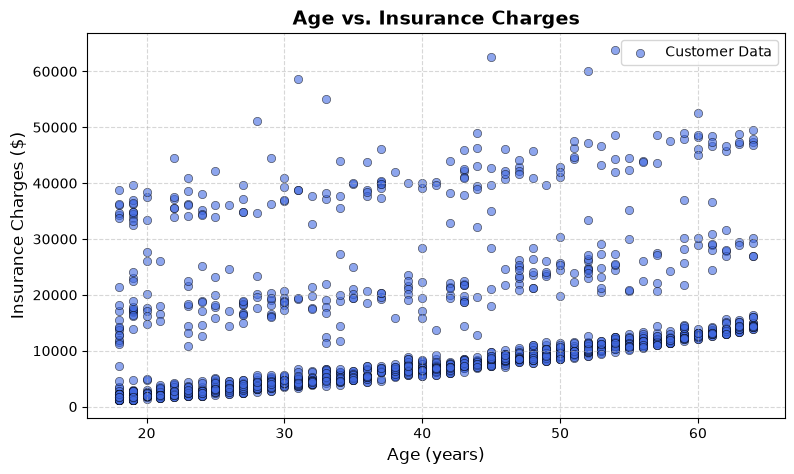

Observation:
1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.
2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")
plt.figure(figsize=(9, 5))
plt.scatter(dataset["age"], dataset["charges"], color="royalblue", alpha=0.6, edgecolors="k", linewidth=0.5, label="Customer Data")
plt.title("Age vs. Insurance Charges", fontsize=14, fontweight="bold")
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Insurance Charges ($)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print("Observation:")
print("1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.")
print("2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).")

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")

Y = dataset["charges"]
X = dataset[["age"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

print("Model Training Completed Successfully!")
print(f"Slope (Coefficient): {slope:.4f}")
print(f"Intercept:           {intercept:.4f}")
print(f"\nRegression Equation: Charges = ({slope:.2f} * Age) + ({intercept:.2f})")
print(f"Interpretation: For each additional year of age, annual insurance charges increase by approximately ${slope:.2f}.")

Model Training Completed Successfully!
Slope (Coefficient): 240.5966
Intercept:           3876.9287

Regression Equation: Charges = (240.60 * Age) + (3876.93)
Interpretation: For each additional year of age, annual insurance charges increase by approximately $240.60.


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")

X_train, X_test, y_train, y_test = train_test_split(
    dataset[["age"]], dataset["charges"], test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

results = pd.DataFrame({
    "Actual": y_test.values, 
    "Predicted": model.predict(X_test)
})

print(results.head(10))

        Actual     Predicted
0   9095.06825  14703.773875
1   5272.17580  12538.404837
2  29330.98315  19275.108511
3   9301.89355  14944.370434
4  33750.29180   8448.263320
5   4536.25900  12057.211717
6   2117.33885   8448.263320
7  14210.53595  19275.108511
8   3732.62510  10613.632358
9  10264.44210  15666.160114


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
dataset = pd.read_csv(r"C:/Users/sakth/Downloads/archive/insurance.csv")
X_train, X_test, y_train, y_test = train_test_split(dataset[["age"]], dataset["charges"], test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, pred))
print("R2 Score:", r2_score(y_test, pred))

MAE: 9173.258196746589
R2 Score: 0.12408973539501944
